# CreditParity – Step 7
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 7:** Explainability with SHAP – globally and for each application

## Step 7 · Explainability with SHAP

**Why explanations?** In CreditParity, explanations are part of the decision process, not an extra:
- 🟡 In the **yellow zone**, the credit analyst sees which factors drive the default probability.
- 🔴 In the **red zone**, the customer receives the main reasons for the automatic decline and can request a human review (GDPR Art. 22).
- The bank and supervisors can check **what the model has learned overall**.

**SHAP for a logistic regression.** SHAP splits a prediction into the contributions of the individual features. For a linear model with independent features, the SHAP value of a feature *j* is exact and simple:

$$\phi_j = \beta_j \cdot (x_j - \overline{x}_j)$$

i.e. the coefficient times the deviation of the applicant from the average applicant. The contributions are in **log-odds** and add up exactly: *average log-odds + sum of all contributions = the applicant's log-odds*, which the logistic function turns into the default probability. Positive contributions raise the risk, negative ones lower it.

**From model columns to features.** One-hot encoding turns e.g. `CheckingStatus` into several columns. Because SHAP values add up, we sum the columns of each original feature, so every explanation refers to the 20 features the applicant actually filled in.

**Models.** The final model **(c)** (logistic regression with reweighing, Step 5/6) and, for comparison, model **(a)** (all features, no reweighing). Zone boundaries for model (c): 0.16 / 0.65 (Step 5).

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap          # pip install shap (pre-installed in Google Colab)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}
UP_COLOR, DOWN_COLOR = "#C44E52", "#55A868"      # raises risk / lowers risk

T_LOWER, T_UPPER = 0.16, 0.65                     # zone boundaries of model (c), Step 5
SENSITIVE = ["Age", "Sex", "ForeignWorker"]

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 to 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [3]:
def make_model():
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("num", StandardScaler(), numeric)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def age_group(data):
    return pd.cut(data["Age"], [18, 25, 35, 50, 100],
                  labels=["19-25", "26-35", "36-50", "51+"]).astype(str)

def reweighing_weights(data, y_true):
    """Kamiran & Calders reweighing on age group x sex x foreign worker status (as in Steps 5 and 6)."""
    group = age_group(data) + "|" + data["Sex"] + "|" + data["ForeignWorker"]
    w = pd.Series(1.0, index=data.index)
    for g in group.unique():
        for label in [0, 1]:
            m = (group == g) & (y_true == label)
            if m.any():
                w[m] = (group == g).mean() * (y_true == label).mean() / m.mean()
    return w.to_numpy()

model_c = make_model().fit(X_train, y_train,
                           model__sample_weight=reweighing_weights(X_train, y_train))
model_a = make_model().fit(X_train, y_train)
MODELS = {"(c) Reweighing – final": model_c, "(a) All features – comparison": model_a}

In [4]:
def dense(m):
    return m.toarray() if hasattr(m, "toarray") else m

def original_feature(column):
    """Map a model column such as 'cat__CheckingStatus_less_0' to 'CheckingStatus'."""
    name = column.split("__", 1)[1]
    return next(f for f in X.columns if name == f or name.startswith(f + "_"))

class Explainer:
    """SHAP explanations of a fitted pipeline, aggregated to the 20 original features."""
    def __init__(self, pipeline, background):
        self.prep = pipeline.named_steps["prep"]
        self.clf = pipeline.named_steps["model"]
        Z = dense(self.prep.transform(background))
        # all training applications as background -> exact linear SHAP values
        masker = shap.maskers.Independent(Z, max_samples=len(Z))
        self.explainer = shap.LinearExplainer(self.clf, masker)
        self.columns = self.prep.get_feature_names_out()
        self.groups = [original_feature(c) for c in self.columns]

    def __call__(self, data):
        sv = self.explainer(dense(self.prep.transform(data)))
        values = pd.DataFrame(sv.values, columns=self.columns, index=data.index)
        values = values.T.groupby(self.groups).sum().T[X.columns]     # one column per feature
        return values, float(np.atleast_1d(sv.base_values)[0])

explainers = {name: Explainer(m, X_train) for name, m in MODELS.items()}

# Check: base value + sum of contributions = the model's log-odds
shap_c, base_c = explainers["(c) Reweighing – final"](X_test)
log_odds = model_c.decision_function(X_test)
print("Average log-odds (base value):", round(base_c, 3))
print("Max. difference between base + sum(SHAP) and model log-odds:",
      float(np.abs(base_c + shap_c.sum(axis=1) - log_odds).max()))

Average log-odds (base value): -1.001
Max. difference between base + sum(SHAP) and model log-odds: 1.7763568394002505e-15


### a) Global explanation: what drives the model overall?

The mean absolute SHAP value of a feature shows how strongly it moves the predictions on average (test set, 1,000 applications).

In [5]:
shap_test = {name: explainers[name](X_test)[0] for name in MODELS}
importance = pd.DataFrame({name: s.abs().mean() for name, s in shap_test.items()})
importance = importance.sort_values("(c) Reweighing – final", ascending=False)
importance["Share of total (c)"] = importance["(c) Reweighing – final"] / importance["(c) Reweighing – final"].sum()
importance.round(3)

,(c) Reweighing – final,(a) All features – comparison,Share of total (c)
Age,0.865,0.024,0.145
CheckingStatus,0.573,0.492,0.096
EmploymentDuration,0.569,0.543,0.096
OwnsProperty,0.517,0.481,0.087
InstallmentPercent,0.502,0.449,0.084
LoanDuration,0.379,0.363,0.064
Sex,0.336,0.330,0.056
ExistingCreditsCount,0.329,0.312,0.055
CurrentResidenceDuration,0.322,0.301,0.054
ExistingSavings,0.307,0.259,0.051


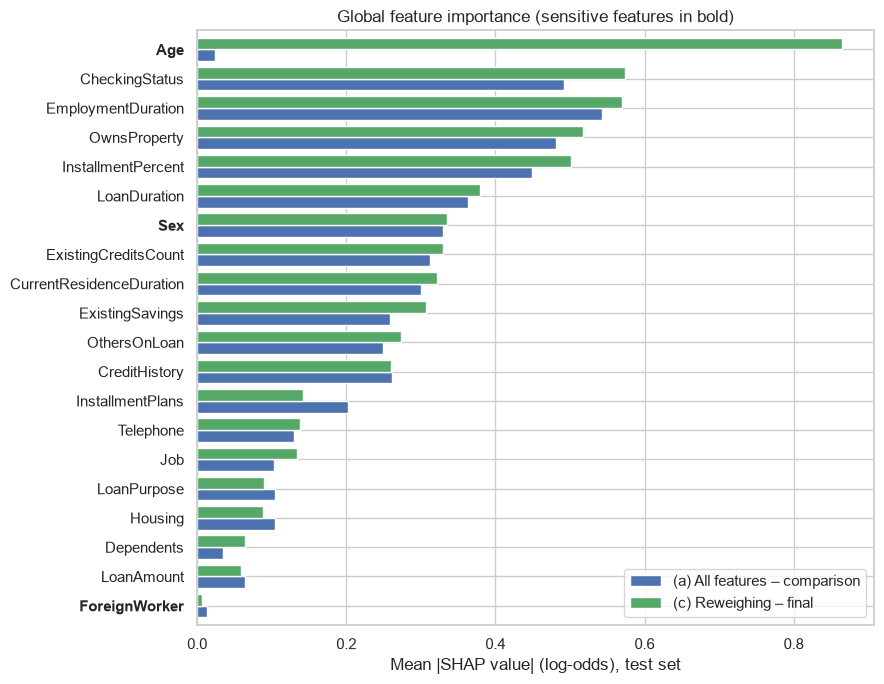

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
plot_df = importance.iloc[::-1][["(a) All features – comparison", "(c) Reweighing – final"]]
plot_df.plot.barh(ax=ax, color=["#4C72B0", "#55A868"], width=0.8)
for label in ax.get_yticklabels():
    if label.get_text() in SENSITIVE:
        label.set_fontweight("bold")
ax.set_xlabel("Mean |SHAP value| (log-odds), test set")
ax.set_title("Global feature importance (sensitive features in bold)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [7]:
# Direction of the sensitive features: coefficients of both models
coef = pd.DataFrame({name: pd.Series(m.named_steps["model"].coef_[0],
                                     index=m.named_steps["prep"].get_feature_names_out())
                     for name, m in MODELS.items()})
coef.index = [c.split("__", 1)[1] for c in coef.index]
coef.loc[[c for c in coef.index if c.startswith(tuple(SENSITIVE))]].round(3)

,(c) Reweighing – final,(a) All features – comparison
Sex_female,0.210,0.213
Sex_male,-0.503,-0.488
ForeignWorker_no,-0.217,0.002
ForeignWorker_yes,-0.077,-0.277
Age,-1.057,0.030


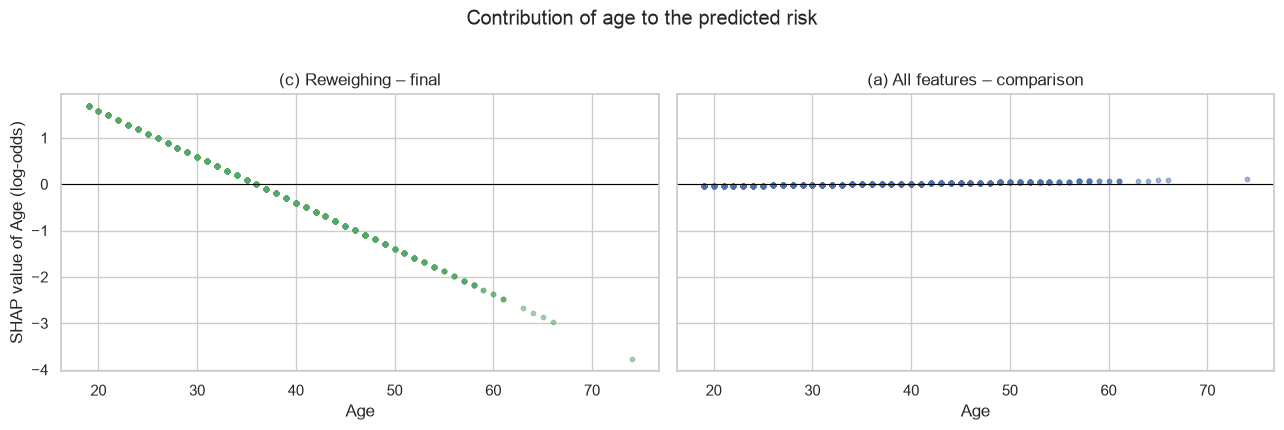

In [8]:
# How does age contribute in each model? SHAP value of Age vs. age
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (name, s) in zip(axes, shap_test.items()):
    ax.scatter(X_test["Age"], s["Age"], s=10, alpha=0.5,
               color="#55A868" if "(c)" in name else "#4C72B0")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Age")
axes[0].set_ylabel("SHAP value of Age (log-odds)")
plt.suptitle("Contribution of age to the predicted risk", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# Strongest drivers by category: average SHAP value per category level (model (c), test set)
rows = []
for feat in ["CheckingStatus", "CreditHistory", "EmploymentDuration", "OwnsProperty", "ExistingSavings"]:
    for level, v in shap_test["(c) Reweighing – final"][feat].groupby(X_test[feat]).mean().items():
        rows.append({"Feature": feat, "Value": level, "Mean SHAP": v})
pd.DataFrame(rows).set_index(["Feature", "Value"]).round(3)

Mean SHAP
Feature            Value                            
CheckingStatus     0_to_200                   -0.270
                   greater_200                 0.223
                   less_0                     -0.767
                   no_checking                 0.669
CreditHistory      all_credits_paid_back      -0.534
                   credits_paid_to_date        0.066
                   no_credits                 -2.096
                   outstanding_credit          0.442
                   prior_payments_delayed      0.083
EmploymentDuration 1_to_4                     -0.065
                   4_to_7                      0.244
                   greater_7                   1.151
                   less_1                     -1.079
                   unemployed                 -1.105
OwnsProperty       car_other                   0.347
                   real_estate                -1.194
                   savings_insurance           0.023
                   unknown                     1.021
ExistingSavings    100_to_500                 -0.032
                   500_to_1000                -0.195
                   greater_1000               -0.314
                   less_100                    0.409
                   unknown                    -0.863

**Result (a) – global explanation.**
- **Age is the strongest driver of the fair model (c)** (14.5% of all SHAP contributions), but in the *opposite* direction from what the raw data suggests: its coefficient is **−1.06**, so the older the applicant, the lower the predicted risk. In model (a), age has almost no weight (coefficient +0.03). The SHAP plot shows a straight line: age raises the risk of every applicant up to about 35 and lowers it for everyone older.
- **Why?** Reweighing removes the link between age group and default in the training data. The model then uses `Age` as a **counterweight to the age proxies** found in Step 6. For example, `EmploymentDuration = greater_7` still raises the risk (+1.15 on average), and the age term offsets the part of this effect that comes from the applicant's age. This is how reweighing achieves fairer outcomes, and it is why it does not work without the sensitive features (Step 6).
- **The other main drivers** are the same in both models: checking account status, employment duration, property, installment rate and loan duration.
- **Sex.** The sex coefficients are almost unchanged by reweighing (female +0.21, male −0.50). *Holding all other features equal*, the model still rates women as riskier, the finding from Step 3. The zone shares of women and men are nevertheless almost equal (Step 6), because women's other features are on average more favorable.
- **Foreign worker status** has almost no influence (0.1% of all contributions).
- **Implausible patterns become visible.** Because the dataset is synthetic, some explanations contradict banking intuition: a negative checking balance (`less_0`, −0.77) and having no previous credits (`no_credits`, −2.10) *lower* the risk, while having no checking account (+0.67) and long employment (`greater_7`, +1.15) *raise* it; unemployed applicants get a lower risk (−1.11). SHAP describes the model faithfully; it cannot tell whether what the model learned makes sense. Analysts need to be aware of this.

### b) Local explanation: why this decision for this applicant?

For individual applications, we show the features that move the default probability most, starting from the average applicant. These are the explanations the analyst (yellow zone) and the customer (red zone) will see in the dashboard. We use one typical application from each zone of the test set (the one with the median PD in its zone).

In [10]:
p_test = {name: m.predict_proba(X_test)[:, 1] for name, m in MODELS.items()}

def zone_of(p, lower=T_LOWER, upper=T_UPPER):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def plot_explanation(idx, model_name="(c) Reweighing – final", top=8, ax=None, title=None):
    """Horizontal bar chart of the largest SHAP contributions for one application."""
    contrib, base = explainers[model_name](X_test.loc[[idx]])
    contrib = contrib.iloc[0]
    order = contrib.abs().sort_values(ascending=False).index
    shown = contrib[order[:top]]
    rest = contrib[order[top:]].sum()
    labels = [f"{f} = {X_test.loc[idx, f]}" for f in shown.index] + [f"{len(order) - top} other features"]
    vals = list(shown.values) + [rest]
    pd_ = sigmoid(base + contrib.sum())
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(labels[::-1], vals[::-1], color=[UP_COLOR if v > 0 else DOWN_COLOR for v in vals[::-1]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("SHAP contribution (log-odds); red = raises risk, green = lowers risk")
    zone = zone_of(np.array([pd_]))[0] if "(c)" in model_name else ""
    ax.set_title(title or f"Application {idx}: PD {pd_:.0%} ({zone}) – average PD {sigmoid(base):.0%}")
    return ax

# One typical application per zone (median PD within the zone), final model (c)
zones_c = pd.Series(zone_of(p_test["(c) Reweighing – final"]), index=X_test.index)
pd_c = pd.Series(p_test["(c) Reweighing – final"], index=X_test.index)
examples = {}
for z in ["Green", "Yellow", "Red"]:
    s = pd_c[zones_c == z].sort_values()
    examples[z] = s.index[len(s) // 2]
pd.DataFrame({z: X_test.loc[i] for z, i in examples.items()}).T.assign(
    PD=[pd_c[i] for i in examples.values()],
    Actual=["Default" if y_test[i] == 1 else "Repaid" for i in examples.values()])

,CheckingStatus,LoanDuration,CreditHistory,LoanPurpose,LoanAmount,ExistingSavings,EmploymentDuration,InstallmentPercent,Sex,OthersOnLoan,...,Age,InstallmentPlans,Housing,ExistingCreditsCount,Job,Dependents,Telephone,ForeignWorker,PD,Actual
Green,no_checking,27,prior_payments_delayed,car_used,4877,500_to_1000,less_1,4,female,none,...,48,none,own,1,skilled,1,yes,yes,0.075263,Repaid
Yellow,no_checking,20,credits_paid_to_date,furniture,6585,100_to_500,greater_7,4,male,none,...,40,none,own,1,skilled,1,yes,yes,0.344316,Repaid
Red,less_0,24,prior_payments_delayed,radio_tv,1569,100_to_500,greater_7,3,female,none,...,25,stores,free,2,skilled,1,yes,yes,0.803574,Repaid


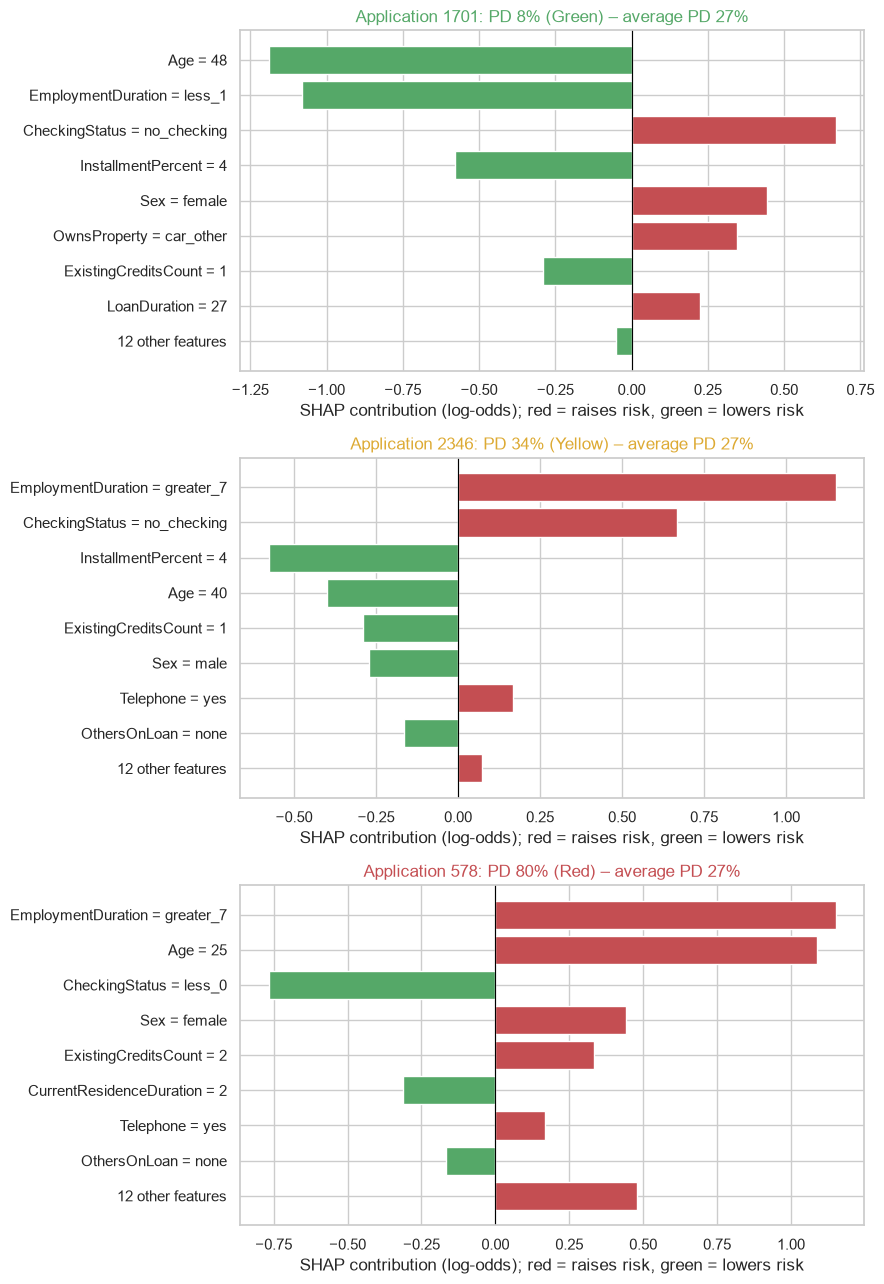

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9, 13))
for ax, (z, idx) in zip(axes, examples.items()):
    plot_explanation(idx, ax=ax)
    ax.title.set_color(ZONE_COLORS[z])
plt.tight_layout()
plt.show()

**Plain-language reasons.** For the dashboard and the analyst's credit memo, we turn the largest contributions into short sentences.

In [12]:
def top_reasons(idx, model_name="(c) Reweighing – final", n=3, exclude=()):
    """The n largest risk-raising and risk-lowering factors as short sentences."""
    contrib = explainers[model_name](X_test.loc[[idx]])[0].iloc[0].drop(list(exclude))
    up = contrib[contrib > 0].sort_values(ascending=False).head(n)
    down = contrib[contrib < 0].sort_values().head(n)
    fmt = lambda f, v: f"{f} = {X_test.loc[idx, f]} ({v:+.2f})"
    return {"Raises risk": [fmt(f, v) for f, v in up.items()],
            "Lowers risk": [fmt(f, v) for f, v in down.items()]}

for z, idx in examples.items():
    r = top_reasons(idx)
    print(f"{z} zone – application {idx}, PD {pd_c[idx]:.0%}")
    print("   Raises risk:", "; ".join(r["Raises risk"]))
    print("   Lowers risk:", "; ".join(r["Lowers risk"]))

Green zone – application 1701, PD 8%
   Raises risk: CheckingStatus = no_checking (+0.67); Sex = female (+0.44); OwnsProperty = car_other (+0.35)
   Lowers risk: Age = 48 (-1.19); EmploymentDuration = less_1 (-1.08); InstallmentPercent = 4 (-0.58)
Yellow zone – application 2346, PD 34%
   Raises risk: EmploymentDuration = greater_7 (+1.15); CheckingStatus = no_checking (+0.67); Telephone = yes (+0.17)
   Lowers risk: InstallmentPercent = 4 (-0.58); Age = 40 (-0.40); ExistingCreditsCount = 1 (-0.29)
Red zone – application 578, PD 80%
   Raises risk: EmploymentDuration = greater_7 (+1.15); Age = 25 (+1.09); Sex = female (+0.44)
   Lowers risk: CheckingStatus = less_0 (-0.77); CurrentResidenceDuration = 2 (-0.31); OthersOnLoan = none (-0.17)


### c) Fair vs. comparison model for an older applicant

Step 6 showed that model (a) declines many creditworthy applicants aged 51+ automatically, while model (c) sends them to an analyst. SHAP shows *why*: we take the good customer aged 51+ from the test set whose PD falls the most between model (a) and model (c), and compare the two explanations.

Application 1587: age 55, actually repaid
  Model (a): PD 63% -> zone Red (boundaries 0.11 / 0.58)
  Model (c): PD 23% -> zone Yellow (boundaries 0.16 / 0.65)


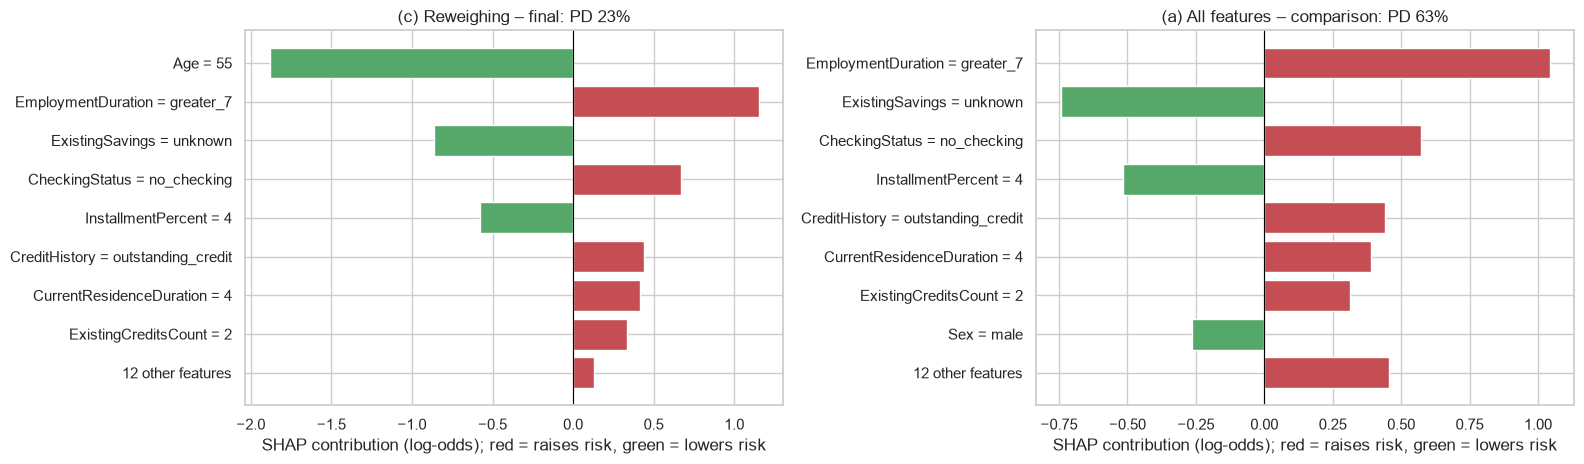

In [13]:
older_good = X_test.index[(X_test["Age"] > 50) & (y_test == 0)]
pd_a = pd.Series(p_test["(a) All features – comparison"], index=X_test.index)
case = (pd_a - pd_c)[older_good].idxmax()
print(f"Application {case}: age {X_test.loc[case, 'Age']}, actually repaid")
print(f"  Model (a): PD {pd_a[case]:.0%} -> zone {zone_of(np.array([pd_a[case]]), 0.11, 0.58)[0]} (boundaries 0.11 / 0.58)")
print(f"  Model (c): PD {pd_c[case]:.0%} -> zone {zone_of(np.array([pd_c[case]]))[0]} (boundaries 0.16 / 0.65)")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, name in zip(axes, MODELS):
    plot_explanation(case, model_name=name, ax=ax,
                     title=f"{name}: PD {(pd_c if '(c)' in name else pd_a)[case]:.0%}")
plt.tight_layout()
plt.show()

### d) Sensitive features in the explanations

In model (c), age, sex and foreign worker status are inputs, so they also appear in the explanations. How often is a sensitive feature among the top 3 drivers of an application?

In [14]:
rows = []
for name, s in shap_test.items():
    top3 = s.abs().apply(lambda r: list(r.sort_values(ascending=False).index[:3]), axis=1)
    rows.append({"Model": name,
                 **{f"{f} in top 3": top3.apply(lambda t: f in t).mean() for f in SENSITIVE},
                 "Any sensitive feature in top 3": top3.apply(lambda t: bool(set(t) & set(SENSITIVE))).mean()})
display(pd.DataFrame(rows).set_index("Model").round(3))

# For which applicants does Age raise the risk in model (c)?
s_c = shap_test["(c) Reweighing – final"]
pd.DataFrame({"Age raises risk": (s_c["Age"] > 0).groupby(age_group(X_test)).mean(),
              "Mean SHAP of Age": s_c["Age"].groupby(age_group(X_test)).mean(),
              "Mean SHAP of Sex": s_c["Sex"].groupby(age_group(X_test)).mean()}).round(3)

,Age in top 3,Sex in top 3,ForeignWorker in top 3,Any sensitive feature in top 3
Model,,,,
(c) Reweighing – final,0.652,0.075,0.0,0.699
(a) All features – comparison,0.000,0.136,0.0,0.136


,Age raises risk,Mean SHAP of Age,Mean SHAP of Sex
Age,,,
19-25,1.0,1.487,0.084
26-35,1.0,0.529,0.003
36-50,0.0,-0.599,-0.016
51+,0.0,-1.880,-0.133


**Result (b–d) – explanations for individual applications.**
- **Typical cases** (test set, model (c)):
  - 🟢 *Green, PD 8%:* a 48-year-old applicant; age (−1.19) and short employment (−1.08) lower the risk most.
  - 🟡 *Yellow, PD 34%:* long employment (+1.15) and no checking account (+0.67) raise the risk; the installment rate and age lower it. This mixed picture is exactly what an analyst should look at.
  - 🔴 *Red, PD 80%:* a 25-year-old woman. The top reasons for the risk are long employment (+1.15), **age 25 (+1.09)** and **sex female (+0.44)**. She actually repaid her loan.
- **Older applicant, fair vs. comparison model.** A 55-year-old good customer gets a PD of 63% from model (a) (red zone, automatic decline) but 23% from model (c) (yellow zone, an analyst decides). The explanation shows why: in model (c), age contributes −1.88 and offsets the risk that model (a) attributes to the age proxies (employment over 7 years, no checking account).
- **Sensitive features appear in most explanations of model (c).** Age is among the top 3 drivers for **65%** of test applications (sex: 8%), so 70% of explanations contain a sensitive feature, compared with 14% for model (a). Age raises the risk of every applicant aged 35 or younger (mean contribution +1.49 for ages 19–25) and lowers it for everyone older (−1.88 for 51+).

**Consequence for CreditParity.** The fair model makes its own fairness correction visible: a young applicant who is declined automatically would read "age" (and possibly "sex") among the main reasons. The explanations are faithful to the model, but showing them to a customer without context can be confusing and is legally sensitive. Two ways to present them in the dashboard:
1. **Full transparency:** show all contributions to both the analyst and the customer.
2. **Analyst sees everything; the customer sees the reasons from the 17 non-sensitive features**, with age, sex and foreign worker status combined into one separate, labeled line ("fairness adjustment"), so the total still adds up.

The choice is a team (and legal) decision; we use it for the dashboard in Step 9.

**Limitations.**
- SHAP explains the **model**, not the causes of default. A feature with a large contribution is not necessarily a reason why someone defaults.
- Contributions are in log-odds and relative to the *average* applicant. They add up exactly, but they cannot be read directly as percentage points of the default probability.
- The linear SHAP values treat features as independent. When features are correlated (e.g. age and its proxies), the split of credit between them is a property of the model's coefficients, which is exactly what we see with `Age` and `EmploymentDuration`.
- Because the dataset is synthetic, some explanations are implausible (see part a).